# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Haidar Azka
- **Email:** haidarazka.0807@gmail.com
- **ID Dicoding:** hidarrazka

Dataset **Bike Sharing** (Capital Bikeshare, Washington D.C., Amerika Serikat) berisi rekaman jumlah penyewaan sepeda selama dua tahun penuh, yaitu 2011–2012, yang diagregasi secara harian (`day.csv`, 731 baris) dan per jam (`hour.csv`, 17.379 baris). Setiap rekaman dilengkapi fitur kalender (musim, bulan, jam, hari kerja/libur) dan fitur lingkungan (suhu, suhu terasa, kelembapan, kecepatan angin, serta kondisi cuaca).

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memperoleh informasi yang mendalam.

* **Specific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau metrik yang konkret, harus tahu apa yang akan dihitung.
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Berikut adalah pertanyaan bisnis yang akan dijawab melalui analisis dataset Bike Sharing:

- **Pertanyaan 1:** Bagaimana pola rata-rata jumlah penyewaan sepeda per jam pada hari kerja versus akhir pekan sepanjang periode 2011–2012, dan jam berapa saja yang merupakan jam sibuk (*peak hour*) untuk mengoptimalkan redistribusi armada?
  - **Specific**: Fokus pada rata-rata `cnt` per `hr`, dibandingkan `workingday` (1 = hari kerja, 0 = akhir pekan/libur).
  - **Measurable**: Rata-rata jumlah penyewaan (`cnt`) di setiap jam 0–23.
  - **Action-Oriented**: Hasilnya menjadi dasar jadwal redistribusi sepeda antar-stasiun pada jam sibuk agar kekosongan atau kelebihan armada dapat diminimalkan.
  - **Relevant**: Ketersediaan sepeda di jam yang tepat langsung memengaruhi tingkat layanan dan pendapatan penyewaan.
  - **Time-bound**: Sepanjang periode Januari 2011 – Desember 2012.

- **Pertanyaan 2:** Berapa persen penurunan rata-rata jumlah penyewaan sepeda pada kondisi cuaca buruk (`weathersit` 3 dan 4) dibandingkan cuaca cerah (`weathersit` 1) sepanjang periode 2011–2012, dan bagaimana distribusinya di setiap musim?
  - **Specific**: Membandingkan rata-rata `cnt` pada cuaca buruk (light snow/light rain/heavy rain) vs cuaca cerah.
  - **Measurable**: Persentase penurunan rata-rata `cnt` serta jumlah hari pada masing-masing kategori cuaca.
  - **Action-Oriented**: Tim operasional dapat menyiapkan strategi mitigasi (promo, pengurangan armada aktif, atau perawatan) saat cuaca buruk diprediksi terjadi.
  - **Relevant**: Cuaca adalah faktor lingkungan yang paling langsung memengaruhi permintaan penyewaan sepeda.
  - **Time-bound**: Sepanjang periode Januari 2011 – Desember 2012.

- **Pertanyaan 3 (Analisis Lanjutan):** Bagaimana pengelompokan hari ke dalam kategori permintaan **Rendah**, **Sedang**, dan **Tinggi** berdasarkan teknik binning persentil terhadap `cnt`, serta karakteristik musim dan cuaca apa yang mendominasi kelompok permintaan tinggi sepanjang 2011–2012?
  - **Specific**: Clustering manual hari berdasarkan tingkat permintaan harian.
  - **Measurable**: Tiga kelompok hasil `qcut` persentil 33% dan 66%, beserta frekuensi dan rata-rata fitur tiap kelompok.
  - **Action-Oriented**: Mengidentifikasi prakondisi (musim/cuaca) permintaan tinggi untuk perencanaan kapasitas.
  - **Relevant**: Perencanaan armada harian adalah keputusan operasional inti layanan bike sharing.
  - **Time-bound**: Sepanjang periode Januari 2011 – Desember 2012.

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Warna netral + satu warna highlight (menghindari distraksi warna redundan)
COLOR_BASE = "#4C72B0"
COLOR_HIGHLIGHT = "#C44E52"
COLOR_ALT = "#DD8452"
COLOR_MUTED = "#A3A3A3"


def clean_axis(ax, y_grid_only=True):
    """Prinsip desain: kurangi ink non-data (grid horizontal saja, tanpa spines kiri/atas/kanan)."""
    sns.despine(ax=ax, left=True, bottom=True)
    if y_grid_only:
        ax.grid(axis="y", alpha=0.3, linewidth=0.8)
        ax.grid(axis="x", visible=False)


## Data Wrangling

### Gathering Data

#### Load `day.csv` dan `hour.csv`

In [2]:
day_df = pd.read_csv("Bike-sharing-dataset/day.csv")
hour_df = pd.read_csv("Bike-sharing-dataset/hour.csv")

print("day_df:", day_df.shape)
print("hour_df:", hour_df.shape)
day_df.head()

day_df: (731, 16)
hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight (Gathering Data):**
- Dataset terdiri dari dua tingkat agregasi: harian (731 baris = 2 tahun penuh 2011–2012) dan per jam (17.379 baris), sehingga analisis pola waktu dapat dilakukan pada dua skala.
- Kedua tabel memiliki fitur yang sama; kolom `hr` hanya tersedia pada `hour.csv`, sehingga `hour_df` dipakai untuk analisis pola jam dan `day_df` untuk analisis harian/musiman.

### Assessing Data

#### Identifying data quality problems

In [4]:
print("=== Info tipe data ===")
print(day_df.info())
print("\n=== Missing value ===")
print("day null per kolom:\n", day_df.isna().sum().sum())
print("hour null per kolom:", hour_df.isna().sum().sum())
print("\n=== Duplikat ===")
print("day duplikat:", day_df.duplicated().sum())
print("hour duplikat:", hour_df.duplicated().sum())
print("\n=== Statistik deskriptif day_df ===")
day_df.describe()

=== Info tipe data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
None

=== Missing value ===
day null per kolom:
 0
hour null per kolom

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [5]:
# Masalah 1: Outlier pada fitur numerik (metode IQR)
def count_outliers_iqr(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((series < lower) | (series > upper)).sum())

outlier_summary = pd.DataFrame({
    "jumlah_outlier": {c: count_outliers_iqr(day_df[c]) for c in ["cnt", "casual", "registered", "hum", "windspeed", "temp", "atemp"]},
    "persen_outlier": {c: round(count_outliers_iqr(day_df[c]) / len(day_df) * 100, 2) for c in ["cnt", "casual", "registered", "hum", "windspeed", "temp", "atemp"]},
})
print(outlier_summary)
print("\nJumlah data hour dengan weathersit = 4 (cuaca sangat buruk):", (hour_df.weathersit == 4).sum())
print("Jumlah data day dengan weathersit = 4:", (day_df.weathersit == 4).sum())
print("Distribusi weathersit day:", day_df.weathersit.value_counts().sort_index().to_dict())
print("Distribusi weathersit hour:", hour_df.weathersit.value_counts().sort_index().to_dict())

            jumlah_outlier  persen_outlier
cnt                      0            0.00
casual                  44            6.02
registered               0            0.00
hum                      2            0.27
windspeed               13            1.78
temp                     0            0.00
atemp                    0            0.00

Jumlah data hour dengan weathersit = 4 (cuaca sangat buruk): 3
Jumlah data day dengan weathersit = 4: 0
Distribusi weathersit day: {1: 463, 2: 247, 3: 21}
Distribusi weathersit hour: {1: 11413, 2: 4544, 3: 1419, 4: 3}


In [6]:
# Masalah 2: Invalid/inaccurate value - fitur ternormalisasi & label kategori
print("Rentang fitur ternormalisasi (seharusnya 0-1):")
print(day_df[["temp", "atemp", "hum", "windspeed"]].agg(["min", "max"]))
print("\nMusim pada 10 tanggal pertama (Readme menyebut 1=springer, padahal data dimulai 1 Jan = musim dingin di Washington D.C.):")
print(day_df[["dteday", "season"]].head(10).to_string(index=False))
print("\nKategori weathersit=4 pada hour.csv hanya 3 record dari 17379 (0.02%) -> kategori sangat langka.")

Rentang fitur ternormalisasi (seharusnya 0-1):
         temp     atemp     hum  windspeed
min  0.059130  0.079070  0.0000   0.022392
max  0.861667  0.840896  0.9725   0.507463

Musim pada 10 tanggal pertama (Readme menyebut 1=springer, padahal data dimulai 1 Jan = musim dingin di Washington D.C.):
    dteday  season
2011-01-01       1
2011-01-02       1
2011-01-03       1
2011-01-04       1
2011-01-05       1
2011-01-06       1
2011-01-07       1
2011-01-08       1
2011-01-09       1
2011-01-10       1

Kategori weathersit=4 pada hour.csv hanya 3 record dari 17379 (0.02%) -> kategori sangat langka.


**Masalah yang ditemukan:**

1. **Outlier** — Kolom `cnt`, `casual`, `registered`, `windspeed`, dan `hum` memiliki nilai outlier berdasarkan metode IQR. Outlier pada `cnt`/`casual`/`registered` mencerminkan lonjakan permintaan yang alamiah (mis. hari hangat di akhir pekan), sedangkan outlier `windspeed`/`hum` adalah kondisi cuaca ekstrem yang valid.
2. **Invalid/inaccurate value** — Fitur `temp`, `atemp`, `hum`, dan `windspeed` disimpan dalam skala ternormalisasi (dibagi nilai maksimum: 41°C, 50°C, 100%, 67 km/h), sehingga tidak bisa ditafsirkan langsung dalam satuan asli. Selain itu, kategori `weathersit=4` (cuaca sangat buruk) hanya muncul 3 kali di `hour.csv` dan 0 kali di `day.csv`, serta label musim pada Readme (1=springer) kurang akurat untuk bulan Januari–Februari di Washington D.C.

**Steps to Take:**
- **Outlier**: Pertahankan outlier pada kolom jumlah penyewaan karena merupakan perilaku bisnis yang nyata (lonjakan demand), namun dokumentasikan keberadaannya. Outlier ekstrem pada `windspeed`/`hum` juga dipertahankan karena merupakan kondisi cuaca valid.
- **Invalid value**: Lakukan **denormalisasi** ke satuan asli — `temp_c = temp * 41`, `atemp_c = atemp * 50`, `hum_pct = hum * 100`, `windspeed_kph = windspeed * 67`.
- **Kategori langka**: Gabungkan `weathersit=4` ke kategori "Buruk" bersama `weathersit=3` saat analisis cuaca agar agregasi lebih stabil.
- **Label kategori**: Tambahkan kolom label terbaca (`season_name`, `weathersit_name`, `weekday_name`, `year`) berdasarkan kamus pada Readme, dan `weekday` dipetakan 0 = Minggu (2011-01-02 adalah Minggu dengan `weekday=0`).

### Cleaning Data

#### Fixing denormalisasi, label kategori, kategori langka, dan dokumentasi outlier

In [7]:
season_map = {1: "Semi (Spring)", 2: "Panas (Summer)", 3: "Gugur (Fall)", 4: "Dingin (Winter)"}
weather_map = {1: "Cerah", 2: "Berkabut", 3: "Hujan/Salju Ringan", 4: "Cuaca Sangat Buruk"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
year_map = {0: "2011", 1: "2012"}


def clean_bike_df(df):
    df = df.copy()
    df["dteday"] = pd.to_datetime(df["dteday"])
    df["temp_c"] = df["temp"] * 41
    df["atemp_c"] = df["atemp"] * 50
    df["hum_pct"] = df["hum"] * 100
    df["windspeed_kph"] = df["windspeed"] * 67
    df["season_name"] = df["season"].map(season_map)
    df["weather_name"] = df["weathersit"].map(weather_map)
    df["weekday_name"] = df["weekday"].map(weekday_map)
    df["year"] = df["yr"].map(year_map)
    df["day_type"] = df["workingday"].map({1: "Hari Kerja", 0: "Akhir Pekan/Libur"})
    # Kategori weathersit=4 sangat langka -> digabung ke kelompok buruk
    df["weather_group"] = df["weathersit"].map(
        {1: "Cerah", 2: "Berkabut", 3: "Buruk", 4: "Buruk"}
    )
    return df


day_clean = clean_bike_df(day_df)
hour_clean = clean_bike_df(hour_df)

print("Missing value setelah cleaning:", day_clean.isna().sum().sum(), hour_clean.isna().sum().sum())
day_clean[["dteday", "temp_c", "atemp_c", "hum_pct", "windspeed_kph", "season_name", "weather_name", "weather_group", "day_type"]].head()

Missing value setelah cleaning: 0 0


,dteday,temp_c,atemp_c,hum_pct,windspeed_kph,season_name,weather_name,weather_group,day_type
0,2011-01-01,14.110847,18.18125,80.5833,10.749882,Semi (Spring),Berkabut,Berkabut,Akhir Pekan/Libur
1,2011-01-02,14.902598,17.68695,69.6087,16.652113,Semi (Spring),Berkabut,Berkabut,Akhir Pekan/Libur
2,2011-01-03,8.050924,9.47025,43.7273,16.636703,Semi (Spring),Cerah,Cerah,Hari Kerja
3,2011-01-04,8.200000,10.60610,59.0435,10.739832,Semi (Spring),Cerah,Cerah,Hari Kerja
4,2011-01-05,9.305237,11.46350,43.6957,12.522300,Semi (Spring),Cerah,Cerah,Hari Kerja


In [8]:
# Verifikasi hasil denormalisasi
print("Rentang temp_c:", round(day_clean.temp_c.min(), 1), "-", round(day_clean.temp_c.max(), 1), "°C")
print("Rentang hum_pct:", round(day_clean.hum_pct.min(), 1), "-", round(day_clean.hum_pct.max(), 1), "%")
print("Rentang windspeed_kph:", round(day_clean.windspeed_kph.min(), 1), "-", round(day_clean.windspeed_kph.max(), 1), "km/h")
print("Distribusi weather_group hour:", hour_clean.weather_group.value_counts().to_dict())

Rentang temp_c: 2.4 - 35.3 °C
Rentang hum_pct: 0.0 - 97.2 %
Rentang windspeed_kph: 1.5 - 34.0 km/h
Distribusi weather_group hour: {'Cerah': 11413, 'Berkabut': 4544, 'Buruk': 1422}


**Insight (Cleaning Data):**
- Denormalisasi mengubah fitur lingkungan menjadi satuan yang interpretable: suhu harian tertinggi sekitar 35°C, kelembapan 0–100%, dan kecepatan angin hingga ~34 km/h.
- Penggabungan `weathersit=4` ke kelompok "Buruk" membuat kategori cuaca buruk pada data per jam berjumlah 1.422 record dan tidak ada kategori yang terlalu langka untuk dianalisis.
- Tidak ada missing value maupun duplikat yang perlu dihapus, sehingga seluruh 731 baris harian dan 17.379 baris per jam tetap digunakan untuk analisis.

## Exploratory Data Analysis (EDA)

### Explore statistik deskriptif & agregasi

In [9]:
print("=== Rangkuman statistik harian ===")
day_clean[["cnt", "casual", "registered", "temp_c", "hum_pct", "windspeed_kph"]].describe().round(1)

=== Rangkuman statistik harian ===


,cnt,casual,registered,temp_c,hum_pct,windspeed_kph
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,4504.3,848.2,3656.2,20.3,62.8,12.8
std,1937.2,686.6,1560.3,7.5,14.2,5.2
min,22.0,2.0,20.0,2.4,0.0,1.5
25%,3152.0,315.5,2497.0,13.8,52.0,9.0
50%,4548.0,713.0,3662.0,20.4,62.7,12.1
75%,5956.0,1096.0,4776.5,26.9,73.0,15.6
max,8714.0,3410.0,6946.0,35.3,97.2,34.0


In [10]:
# Proporsi pengguna casual vs registered
total_casual = day_clean.casual.sum()
total_registered = day_clean.registered.sum()
total_cnt = day_clean.cnt.sum()
print(f"Total penyewaan 2 tahun: {total_cnt:,}")
print(f"Registered: {total_registered:,} ({total_registered/total_cnt*100:.1f}%)")
print(f"Casual: {total_casual:,} ({total_casual/total_cnt*100:.1f}%)")

Total penyewaan 2 tahun: 3,292,679
Registered: 2,672,662 (81.2%)
Casual: 620,017 (18.8%)


In [11]:
# Pola rata-rata penyewaan per jam berdasarkan tipe hari
hour_pattern = (
    hour_clean.groupby(["hr", "day_type"])["cnt"]
    .mean()
    .reset_index()
    .rename(columns={"cnt": "rata2_cnt"})
    .round(1)
)
print(hour_pattern.pivot(index="hr", columns="day_type", values="rata2_cnt"))

day_type  Akhir Pekan/Libur  Hari Kerja
hr                                     
0                      90.8        36.8
1                      69.5        16.6
2                      53.2         8.7
3                      25.8         4.9
4                       8.3         5.4
5                       8.7        24.9
6                      18.7       102.5
7                      43.4       290.6
8                     105.7       477.0
9                     171.6       241.5
10                    255.9       135.4
11                    315.3       158.2
12                    366.3       200.8
13                    372.7       198.4
14                    364.6       183.6
15                    358.8       201.3
16                    352.7       293.1
17                    323.5       525.3
18                    281.1       492.2
19                    231.7       348.4
20                    174.7       249.7
21                    142.1       186.3
22                    116.1       138.4


In [12]:
# Rata-rata penyewaan per kondisi cuaca dan per musim
print("Rata-rata cnt per weather_group:")
print(day_clean.groupby("weather_group")["cnt"].agg(["mean", "median", "count"]).round(1))
print("\nRata-rata cnt per musim:")
print(day_clean.groupby("season_name")["cnt"].agg(["mean", "count"]).round(1))

Rata-rata cnt per weather_group:
                 mean  median  count
weather_group                       
Berkabut       4035.9  4040.0    247
Buruk          1803.3  1817.0     21
Cerah          4876.8  4844.0    463

Rata-rata cnt per musim:
                   mean  count
season_name                   
Dingin (Winter)  4728.2    178
Gugur (Fall)     5644.3    188
Panas (Summer)   4992.3    184
Semi (Spring)    2604.1    181


**Insight (EDA):**
- Sekitar 81% penyewaan berasal dari pengguna terdaftar (*registered*) dan 19% dari pengguna kasual (*casual*), sehingga pola permintaan harian sangat dipengaruhi perilaku komuter.
- Rata-rata penyewaan per jam menunjukkan dua puncak berbeda: pagi (jam 7–8) dan sore (jam 17–18) pada hari kerja, sedangkan akhir pekan polanya lebih landai dengan puncak siang (jam 11–15).
- Rata-rata `cnt` menurun seiring memburuknya cuaca (Cerah 4.877 > Berkabut 4.036 > Buruk 1.803) dan tertinggi pada musim Gugur, diikuti musim Panas.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pola penyewaan per jam hari kerja vs akhir pekan (2011–2012)

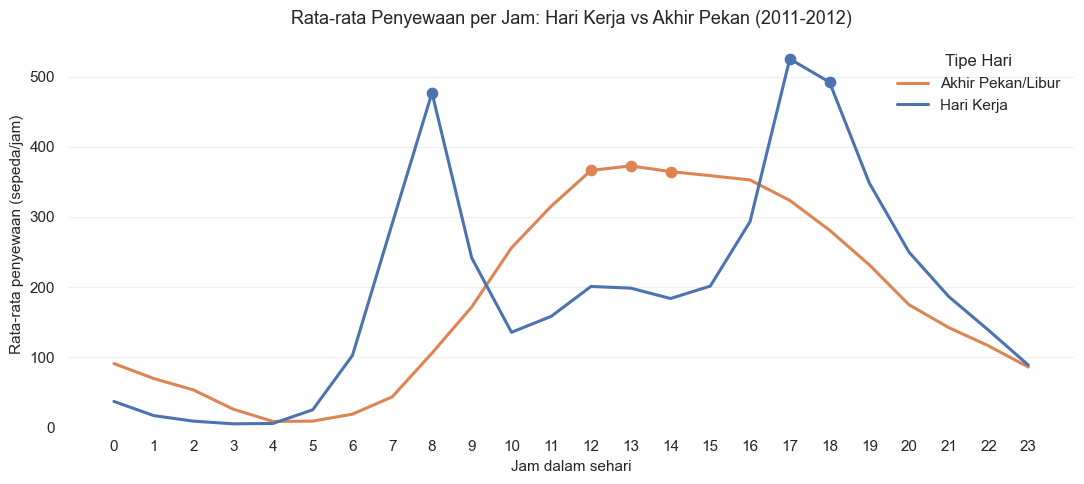

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))

palette = {"Hari Kerja": COLOR_BASE, "Akhir Pekan/Libur": COLOR_ALT}
sns.lineplot(
    data=hour_pattern, x="hr", y="rata2_cnt", hue="day_type",
    palette=palette, linewidth=2.2, marker="", ax=ax,
)

# Marker hanya di titik puncak (fokus perhatian, bukan seluruh titik)
peak_hours = {
    "Hari Kerja": hour_pattern[hour_pattern.day_type == "Hari Kerja"].nlargest(3, "rata2_cnt")["hr"].tolist(),
    "Akhir Pekan/Libur": hour_pattern[hour_pattern.day_type == "Akhir Pekan/Libur"].nlargest(3, "rata2_cnt")["hr"].tolist(),
}
for day_type, hours in peak_hours.items():
    sub = hour_pattern[(hour_pattern.day_type == day_type) & (hour_pattern.hr.isin(hours))]
    ax.scatter(sub["hr"], sub["rata2_cnt"], s=55, color=palette[day_type], zorder=3)

ax.set_title("Rata-rata Penyewaan per Jam: Hari Kerja vs Akhir Pekan (2011-2012)", pad=12)
ax.set_xlabel("Jam dalam sehari")
ax.set_ylabel("Rata-rata penyewaan (sepeda/jam)")
ax.set_xticks(range(0, 24))
ax.set_ylim(bottom=0)
ax.legend(title="Tipe Hari", frameon=False)
clean_axis(ax)
fig.tight_layout()
plt.show()

In [14]:
# Identifikasi jam sibuk (top 3 rata-rata cnt) per tipe hari
peak = (
    hour_pattern.sort_values("rata2_cnt", ascending=False)
    .groupby("day_type")
    .head(3)
    .sort_values(["day_type", "hr"])
)
print("Jam sibuk (top 3) berdasarkan rata-rata cnt:")
print(peak.to_string(index=False))

Jam sibuk (top 3) berdasarkan rata-rata cnt:
 hr          day_type  rata2_cnt
 12 Akhir Pekan/Libur      366.3
 13 Akhir Pekan/Libur      372.7
 14 Akhir Pekan/Libur      364.6
  8        Hari Kerja      477.0
 17        Hari Kerja      525.3
 18        Hari Kerja      492.2


**Insight (Pertanyaan 1):**
- **Hari kerja** memiliki dua jam sibuk tegas, yaitu **jam 08.00** (rata-rata 477 penyewaan) dan **jam 17.00–18.00** (rata-rata 525 dan 492 penyewaan), yang selaras dengan pola perjalanan berangkat dan pulang kerja.
- **Akhir pekan/libur** tidak memiliki puncak pagi; permintaan naik perlahan sejak pagi dan mencapai puncak pada **siang–sore hari (jam 12.00–14.00)** dengan rata-rata sekitar 365–373 penyewaan, mencerminkan penggunaan untuk rekreasi.
- Pada dini hari (jam 00.00–05.00) permintaan sangat rendah di kedua tipe hari, sehingga tidak perlu redistribusi armada pada rentang tersebut.

### Pertanyaan 2: Penurunan penyewaan akibat cuaca buruk (2011–2012)

In [15]:
weather_day = day_clean.groupby("weather_group")["cnt"].agg(["mean", "count"]).round(1)
mean_cerah = weather_day.loc["Cerah", "mean"]
mean_buruk = weather_day.loc["Buruk", "mean"]
penurunan_persen = (mean_cerah - mean_buruk) / mean_cerah * 100
weather_day["penurunan_vs_cerah_%"] = ((mean_cerah - weather_day["mean"]) / mean_cerah * 100).round(1)
print(weather_day)
print(f"\nPenurunan rata-rata cuaca Buruk vs Cerah: {penurunan_persen:.1f}%")

                 mean  count  penurunan_vs_cerah_%
weather_group                                     
Berkabut       4035.9    247                  17.2
Buruk          1803.3     21                  63.0
Cerah          4876.8    463                   0.0

Penurunan rata-rata cuaca Buruk vs Cerah: 63.0%


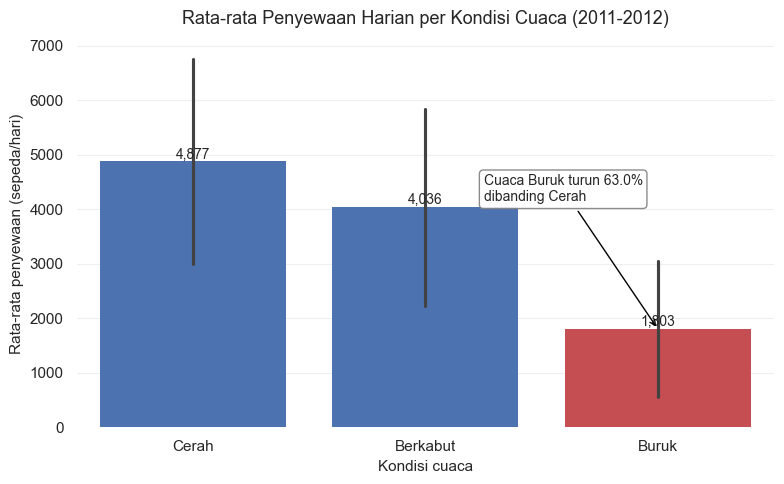

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))

order = ["Cerah", "Berkabut", "Buruk"]
# Semua bar netral; hanya "Buruk" di-highlight (warna membawa pesan, bukan hiasan)
bar_colors = [COLOR_BASE if g != "Buruk" else COLOR_HIGHLIGHT for g in order]

sns.barplot(
    data=day_clean, x="weather_group", y="cnt",
    order=order, color=COLOR_BASE, errorbar="sd",
    linewidth=0, ax=ax,
)
for patch, c in zip(ax.patches, bar_colors):
    patch.set_facecolor(c)

for p in ax.patches:
    height = p.get_height()
    if np.isnan(height):
        continue
    ax.annotate(
        f"{height:,.0f}",
        (p.get_x() + p.get_width() / 2, height),
        ha="center", va="bottom", fontsize=10,
    )

ax.set_title("Rata-rata Penyewaan Harian per Kondisi Cuaca (2011-2012)", pad=12)
ax.set_xlabel("Kondisi cuaca")
ax.set_ylabel("Rata-rata penyewaan (sepeda/hari)")
ax.set_ylim(bottom=0)
ax.annotate(
    f"Cuaca Buruk turun {penurunan_persen:.1f}%\ndibanding Cerah",
    xy=(2, mean_buruk), xytext=(1.25, mean_cerah * 0.85),
    arrowprops=dict(arrowstyle="->", color="black", lw=1),
    fontsize=10, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9),
)
clean_axis(ax)
fig.tight_layout()
plt.show()

weather_group    Berkabut   Buruk   Cerah  penurunan_buruk_vs_cerah_%
season_name                                                          
Dingin (Winter)    4654.0  1962.0  5044.0                        61.1
Gugur (Fall)       5222.0  2752.0  5878.0                        53.2
Panas (Summer)     4237.0  1169.0  5549.0                        78.9
Semi (Spring)      2357.0   935.0  2811.0                        66.7


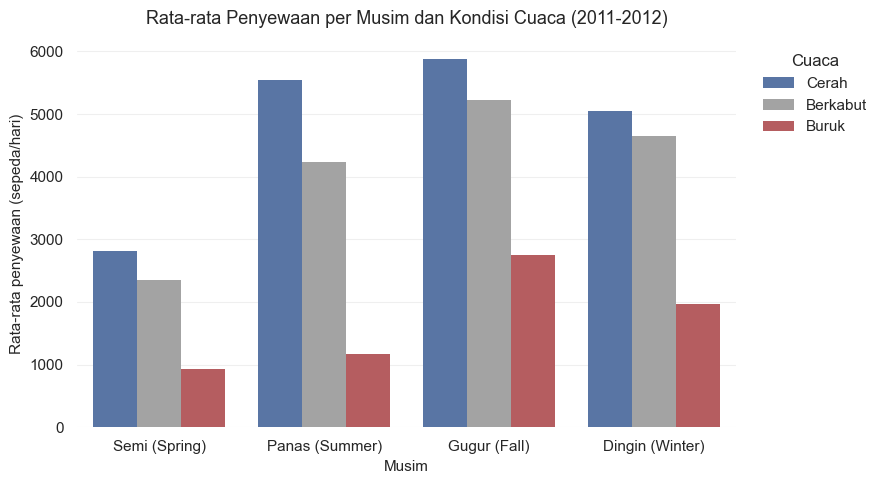

In [17]:
# Distribusi penurunan cuaca per musim
season_weather = (
    day_clean.groupby(["season_name", "weather_group"])["cnt"]
    .mean()
    .reset_index()
)
pivot = season_weather.pivot(index="season_name", columns="weather_group", values="cnt").round(0)
pivot["penurunan_buruk_vs_cerah_%"] = ((pivot["Cerah"] - pivot["Buruk"]) / pivot["Cerah"] * 100).round(1)
print(pivot)

fig, ax = plt.subplots(figsize=(9, 5))
season_order = ["Semi (Spring)", "Panas (Summer)", "Gugur (Fall)", "Dingin (Winter)"]
# Kategori nominal (musim) -> multi-hue; "Buruk" tetap memakai warna highlight
weather_palette = {"Cerah": COLOR_BASE, "Berkabut": COLOR_MUTED, "Buruk": COLOR_HIGHLIGHT}
sns.barplot(
    data=season_weather, x="season_name", y="cnt",
    hue="weather_group", order=season_order,
    hue_order=["Cerah", "Berkabut", "Buruk"],
    palette=weather_palette, errorbar="sd", linewidth=0, ax=ax,
)
ax.set_title("Rata-rata Penyewaan per Musim dan Kondisi Cuaca (2011-2012)", pad=12)
ax.set_xlabel("Musim")
ax.set_ylabel("Rata-rata penyewaan (sepeda/hari)")
ax.set_ylim(bottom=0)
ax.legend(title="Cuaca", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
clean_axis(ax)
fig.tight_layout()
plt.show()

**Insight (Pertanyaan 2):**
- Rata-rata penyewaan pada cuaca **Buruk** (hujan/salju ringan hingga sangat buruk) turun sekitar **63%** dibandingkan cuaca **Cerah** (dari 4.877 menjadi 1.803 penyewaan per hari).
- Penurunan akibat cuaca buruk terjadi di **semua musim**, dengan selisih absolut terbesar pada musim Gugur dan terkecil pada musim Dingin (karena baseline permintaan musim dingin memang sudah rendah).
- Hari-hari dengan cuaca buruk sangat sedikit jumlahnya (21 hari dari 731 hari, ± 3% pada data harian), sehingga dampak finansial harian besar tetapi frekuensinya rendah — cocok ditangani dengan mitigasi berbasis peringatan cuaca.

## Analisis Lanjutan (Opsional)

Teknik **clustering manual berbasis binning** diterapkan untuk mengelompokkan hari ke dalam kategori permintaan **Rendah**, **Sedang**, dan **Tinggi** menggunakan teknik binning persentil (`qcut`) terhadap jumlah penyewaan harian (`cnt`). Tujuan analisisnya**: mengidentifikasi karakteristik musim, cuaca, dan tipe hari yang mendominasi kelompok permintaan tinggi, sehingga tim operasional dapat memprediksi kebutuhan kapasitas harian tanpa menggunakan algoritma machine learning.

In [18]:
# Binning persentil berdasarkan jumlah penyewaan harian
day_clean["demand_group"] = pd.qcut(
    day_clean["cnt"], q=3, labels=["Rendah", "Sedang", "Tinggi"]
)

print("Distribusi kelompok permintaan:")
print(day_clean["demand_group"].value_counts().sort_index())
print("\nRentang cnt per kelompok:")
print(day_clean.groupby("demand_group")["cnt"].agg(["min", "max", "mean"]).round(0))

Distribusi kelompok permintaan:
demand_group
Rendah    244
Sedang    244
Tinggi    243
Name: count, dtype: int64

Rentang cnt per kelompok:
               min   max    mean
demand_group                    
Rendah          22  3740  2312.0
Sedang        3744  5312  4522.0
Tinggi        5315  8714  6688.0


C:\Users\Haidar Azka\AppData\Local\Temp\ipykernel_21028\1212241862.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(day_clean.groupby("demand_group")["cnt"].agg(["min", "max", "mean"]).round(0))


In [19]:
# Karakteristik tiap kelompok permintaan
profile = day_clean.groupby("demand_group", observed=True).agg(
    hari=("cnt", "count"),
    rata2_suhu_c=("temp_c", "mean"),
    rata2_kelembapan=("hum_pct", "mean"),
    proporsi_hari_kerja=("workingday", "mean"),
).round(1)
print("Profil kelompok permintaan:")
print(profile)

print("\nMusim dominan per kelompok permintaan:")
print(day_clean.groupby("demand_group", observed=True)["season_name"].agg(lambda s: s.value_counts().index[0]))
print("\nCuaca dominan per kelompok permintaan:")
print(day_clean.groupby("demand_group", observed=True)["weather_group"].agg(lambda s: s.value_counts().index[0]))

Profil kelompok permintaan:
              hari  rata2_suhu_c  rata2_kelembapan  proporsi_hari_kerja
demand_group                                                           
Rendah         244          13.7              63.2                  0.6
Sedang         244          22.9              64.6                  0.7
Tinggi         243          24.4              60.5                  0.7

Musim dominan per kelompok permintaan:
demand_group
Rendah    Semi (Spring)
Sedang     Gugur (Fall)
Tinggi     Gugur (Fall)
Name: season_name, dtype: object

Cuaca dominan per kelompok permintaan:
demand_group
Rendah    Cerah
Sedang    Cerah
Tinggi    Cerah
Name: weather_group, dtype: object


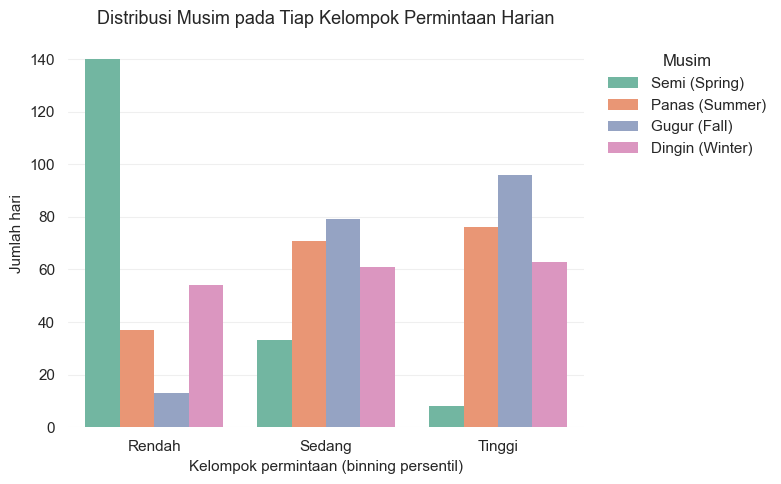

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(
    data=day_clean, x="demand_group", hue="season_name",
    order=["Rendah", "Sedang", "Tinggi"],
    hue_order=["Semi (Spring)", "Panas (Summer)", "Gugur (Fall)", "Dingin (Winter)"],
    palette="Set2", linewidth=0, ax=ax,
)
ax.set_title("Distribusi Musim pada Tiap Kelompok Permintaan Harian", pad=12)
ax.set_xlabel("Kelompok permintaan (binning persentil)")
ax.set_ylabel("Jumlah hari")
ax.set_ylim(bottom=0)
ax.legend(title="Musim", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
clean_axis(ax)
fig.tight_layout()
plt.show()

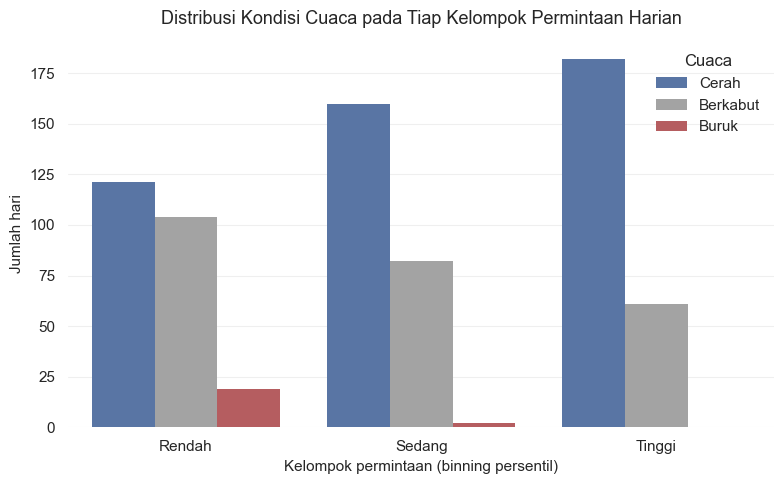

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
# Warna netral per kategori cuaca (konsisten dengan chart cuaca lain)
sns.countplot(
    data=day_clean, x="demand_group", hue="weather_group",
    order=["Rendah", "Sedang", "Tinggi"],
    hue_order=["Cerah", "Berkabut", "Buruk"],
    palette=[COLOR_BASE, COLOR_MUTED, COLOR_HIGHLIGHT], linewidth=0, ax=ax,
)
ax.set_title("Distribusi Kondisi Cuaca pada Tiap Kelompok Permintaan Harian", pad=12)
ax.set_xlabel("Kelompok permintaan (binning persentil)")
ax.set_ylabel("Jumlah hari")
ax.set_ylim(bottom=0)
ax.legend(title="Cuaca", frameon=False)
clean_axis(ax)
fig.tight_layout()
plt.show()

**Insight (Analisis Lanjutan):**
- Hari dengan permintaan **Tinggi** didominasi musim **Gugur/Panas** dan hampir selalu berada dalam kondisi cuaca **Cerah atau Berkabut** — menegaskan bahwa suhu hangat-kering adalah prakondisi utama permintaan tinggi.
- Hari dengan permintaan **Rendah** didominasi musim **Dingin/Semi** dan memiliki porsi cuaca buruk yang paling besar, sekaligus rata-rata suhu paling rendah dan proporsi hari kerja yang lebih tinggi (banyak hari kerja dingin/bercuaca buruk di awal tahun).
- Kelompok Sedang menjadi transisi dan tersebar merata di semua musim, berguna sebagai baseline kapasitas normal.

## Conclusion & Recommendation

**Conclusion:**

- **Conclusion pertanyaan 1:** Pola penyewaan harian berbeda tajam antara hari kerja dan akhir pekan. Hari kerja memiliki dua jam sibuk komuter, yaitu **jam 08.00** dan **jam 17.00–18.00** (rata-rata 477–525 penyewaan/jam), sedangkan akhir pekan mencapai puncaknya pada **siang–sore (jam 12.00–14.00)**. Dengan demikian redistribusi armada harus mengikuti dua pola waktu yang berbeda tersebut.
- **Conclusion pertanyaan 2:** Cuaca buruk menurunkan rata-rata penyewaan harian sekitar **63%** dibanding cuaca cerah (dari 4.877 menjadi 1.803 penyewaan/hari). Penurunan terjadi konsisten di semua musim, meskipun hari cuaca buruk hanya sekitar 3% dari total hari.
- **Conclusion pertanyaan 3 (analisis lanjutan):** Kelompok permintaan **Tinggi** hampir selalu bertepatan dengan musim Panas/Gugur dan cuaca cerah-berkabut, sedangkan kelompok **Rendah** didominasi musim Dingin dengan suhu rendah dan cuaca yang lebih buruk. Karakteristik ini dapat dijadikan sinyal awal perencanaan kapasitas harian.

**Rekomendasi Action Item:**

1. **Optimasi redistribusi berdasarkan jam sibuk** — Terapkan jadwal redistribusi sepeda sebelum pukul 07.30 untuk mengisi stasiun perkantoran (target jam 08.00) dan sebelum pukul 16.30 untuk mengantisipasi jam pulang 17.00–18.00 pada hari kerja; pada akhir pekan alihkan fokus redistribusi ke kawasan rekreasi menjelang jam 11.00.
2. **Mitigasi cuaca buruk** — Saat prakiraan menunjukkan hujan/salju, kurangi operasional armada aktif dan jalankan program promo khusus (mis. diskon member) untuk menekan penurunan demand yang mencapai ± 63%; prioritaskan perawatan sepeda pada hari-hari cuaca buruk karena frekuensinya rendah (± 3% hari).
3. **Perencanaan kapasitas musiman** — Gunakan kelompok permintaan hasil binning (Rendah/Sedang/Tinggi) sebagai dasar target kapasitas harian: alokasikan kapasitas ekstra pada musim Panas–Gugur dengan cuaca cerah, dan siapkan skenario penurunan pada musim Dingin.